# Coaching Class – Student Performance Analysis
## Seaborn Session 9 – Regression Plots

This project analyzes 150 fictional students using Seaborn regression plots, LOWESS smoothing, and batch-wise performance analysis.

Task 1: Generate 150 student records

   student_id    batch  study_hours_week  attendance_pct      marks
0           1  Morning              12.5              92  47.045951
1           2  Morning              28.6              60  82.052028
2           3  Morning              22.5              78  72.130732
3           4  Morning              18.8              61  54.606574
4           5  Morning               6.4              85  43.816695
Total Students: 150


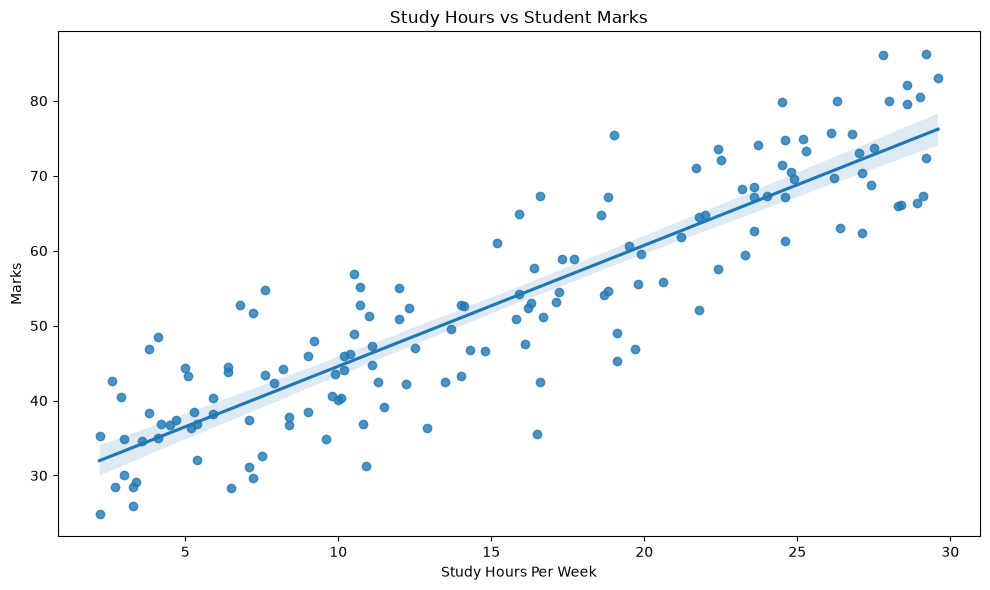

Regression Slope: 1.614
Task 1 Completed!


In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

# Create student IDs
student_id = np.arange(1, 151)

# Create 3 batches with 50 students each
batch = np.repeat(
    ["Morning", "Evening", "Weekend"],
    50
)

# Weekly study hours
study_hours_week = np.round(
    np.random.uniform(2, 30, 150),
    1
)

# Attendance percentage
attendance_pct = np.random.randint(
    60, 101, 150
)

# Batch offsets
batch_offset = np.where(
    batch == "Morning", 3,
    np.where(batch == "Evening", 0, -4)
)

# Generate marks
marks = (
    25
    + 1.6 * study_hours_week
    + 0.15 * (attendance_pct - 60)
    + batch_offset
    + np.random.normal(0, 6, 150)
)

# Keep marks between 0 and 100
marks = np.clip(marks, 0, 100)

# Create DataFrame
df = pd.DataFrame({
    "student_id": student_id,
    "batch": batch,
    "study_hours_week": study_hours_week,
    "attendance_pct": attendance_pct,
    "marks": marks
})

# Save CSV
df.to_csv("coaching_marks.csv", index=False)

print(df.head())
print("Total Students:", len(df))

# Regression plot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="study_hours_week",
    y="marks"
)

plt.title("Study Hours vs Student Marks")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Marks")

plt.tight_layout()
plt.show()

# Calculate regression slope
slope = np.polyfit(
    df["study_hours_week"],
    df["marks"],
    1
)[0]

print("Regression Slope:", round(slope, 3))
print("Task 1 Completed!")


Task 2: Linear regression vs LOWESS smoothing

RuntimeError: `lowess=True` requires statsmodels, an optional dependency, to be installed.

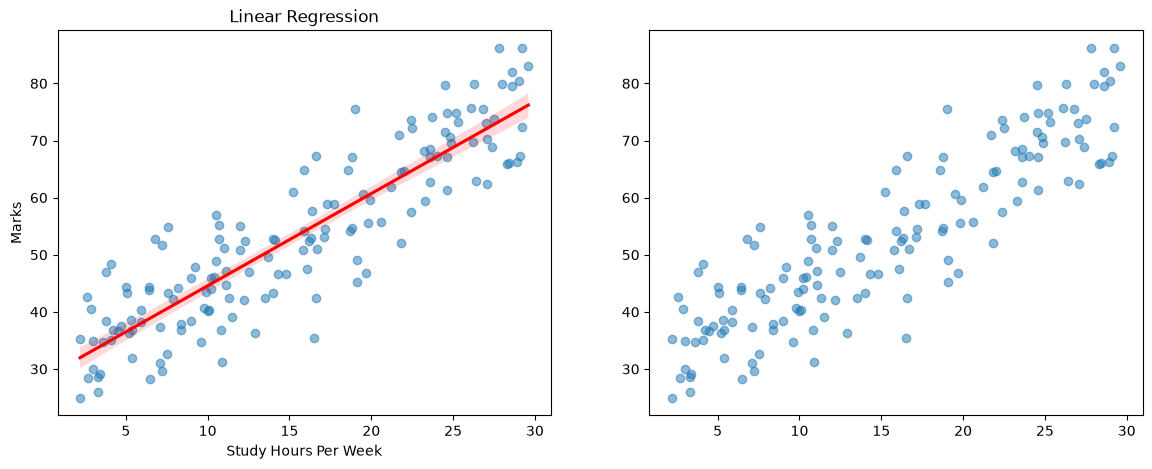

In [2]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Straight-line regression
sns.regplot(
    data=df,
    x="study_hours_week",
    y="marks",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[0]
)

axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Study Hours Per Week")
axes[0].set_ylabel("Marks")

# LOWESS smoothing
sns.regplot(
    data=df,
    x="study_hours_week",
    y="marks",
    lowess=True,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[1]
)

axes[1].set_title("LOWESS Smoothing")
axes[1].set_xlabel("Study Hours Per Week")
axes[1].set_ylabel("Marks")

plt.tight_layout()

plt.savefig(
    "coaching_lowess.png",
    dpi=150
)

plt.show()

print("Task 2 Completed!")


Task 3: Regression plots by batch

In [ ]:

# Separate regression plot for each batch
g = sns.lmplot(
    data=df,
    x="study_hours_week",
    y="marks",
    col="batch",
    height=4,
    aspect=1
)

g.figure.suptitle(
    "Study Hours vs Marks by Batch",
    y=1.03
)

g.set_axis_labels(
    "Study Hours Per Week",
    "Marks"
)

g.savefig(
    "coaching_lmplot_batches.png",
    dpi=150
)

plt.show()

print("Task 3 Completed!")


Task 4: Attendance vs marks and batch-wise slopes

In [ ]:

# Final regression plot
g = sns.lmplot(
    data=df,
    x="attendance_pct",
    y="marks",
    hue="batch",
    ci=None,
    height=6,
    aspect=1.3
)

g.figure.suptitle(
    "Attendance vs Student Marks by Batch",
    y=1.02
)

g.set_axis_labels(
    "Attendance Percentage",
    "Marks"
)

g.savefig(
    "coaching_attendance_final.png",
    dpi=150
)

plt.show()

# Calculate regression slope for each batch
print("BATCH-WISE REGRESSION SLOPES")
print("-" * 40)

print(f"{'Batch':<15}{'Slope':>12}")

for batch_name, group in df.groupby("batch"):

    slope = np.polyfit(
        group["attendance_pct"],
        group["marks"],
        1
    )[0]

    print(f"{batch_name:<15}{slope:>12.3f}")

print("\nTask 4 Completed!")
print("Session 9 Completed Successfully!")
